Jumlah data kosong: 0
=== HASIL EVALUASI MODEL GAUSSIAN NAIVE BAYES ===
Akurasi Model : 97.22%

Classification Report:
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



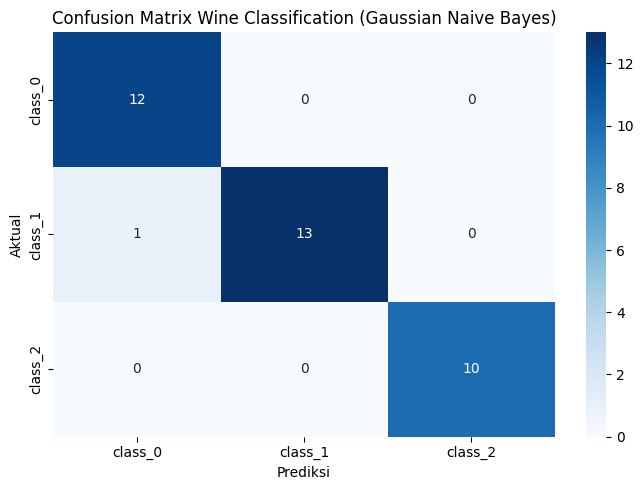

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. LOAD DATASET (Scikit-Learn Wine Dataset)
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name='class')

# 2. PEMBERSIHAN DATA & PREPROCESSING
# Cek missing values
print("Jumlah data kosong:", X.isnull().sum().sum())

# Train-Test Split (80:20)
# Catatan: Naive Bayes bekerja secara probabilistik sehingga scaling tidak wajib,
# namun pembagian data tetap menggunakan stratify agar seimbang.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. TRAINING MODEL GAUSSIAN NAIVE BAYES
model = GaussianNB()
model.fit(X_train, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"=== HASIL EVALUASI MODEL GAUSSIAN NAIVE BAYES ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=wine.target_names))

# 5. VISUALISASI CONFUSION MATRIX
fig, ax = plt.subplots(figsize=(7, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=ax,
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_title("Confusion Matrix Wine Classification (Gaussian Naive Bayes)")

plt.tight_layout()
plt.show()